# The Hertzsprung–Russell Diagram from Hipparcos: Statistical Modelling of Stellar Populations

**Author:** Stylianos Stamatis · MSc Machine Learning (University of Thessaly), *Mathematical Modelling II* project

The ESA Hipparcos satellite (1989–1993) measured parallaxes and photometry for ~118,000 nearby stars.
From apparent magnitude $V$ and parallax $\pi$ we compute each star's absolute magnitude and build the
**Hertzsprung–Russell (HR) diagram**, then model it statistically.

| # | Task | Methods |
|---|------|---------|
| 1 | HR diagram & marginal distributions | descriptive statistics, 1-D Gaussian mixtures |
| 2 | Solar-colour stars as $\mathcal N(\mu,\sigma^2)$ | MLE derivation, bias of $\hat\sigma^2$, Q–Q plot |
| 3 | Bayesian estimate of $\mu$ | Gaussian–Gaussian conjugate prior (the Sun as prior) |
| 4 | Main-sequence relation | **data-driven sample selection**, OLS via normal equations, diagnostics |
| 5 | Giant vs main-sequence classifier | L2 logistic regression on colour and apparent magnitude, 5-fold CV |
| 6 | Evaluation for a standard-candle use case | precision-weighted threshold (F0.5), train/validation loss curves |
| 7 | Linear vs cubic main sequence | AIC & BIC from first principles |
| 8 | Stellar populations | Gaussian mixture model, BIC, population identification |
| 9 | P(star brighter than the Sun) | analytic Gaussian CDF vs Monte Carlo |
| 11 | Parallax error propagation | delta method, Monte Carlo sensitivity, Lutz–Kelker simulation |

Task 10 of the brief (Mira light curve from AAVSO) was optional and is not included.
All random operations use `SEED = 42`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (confusion_matrix, f1_score, fbeta_score, log_loss, precision_score,
                             recall_score, roc_auc_score, average_precision_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
M_SUN = 4.83          # absolute V magnitude of the Sun

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def hr_axes(ax, title=None):
    ax.set_xlabel("B − V (colour index; hot → cool)"); ax.set_ylabel("$M_V$ (absolute magnitude)")
    if not ax.yaxis_inverted():
        ax.invert_yaxis()
    if title: ax.set_title(title)

## Data

Columns `HIP, Vmag, B-V, Plx, e_Plx` from the Hipparcos main catalogue (ESA 1997, VizieR `I/239/hip_main`).
The loader uses `data/hip_main.csv` if present. Otherwise it tries the VizieR servers and, if they do not respond,
the same catalogue in the **ESA Gaia archive** (`public.hipparcos`), queried in HIP ranges because of its 50,000-row limit.

**Pre-processing (from the brief):** drop missing values; drop $\pi \le 0$ (needed for the logarithm);
compute $M_V = V + 5\log_{10}\pi - 10$ ($\pi$ in mas); keep stars with relative parallax error $\sigma_\pi/\pi < 0.1$.

In [2]:
DATA_PATH = ROOT / "data" / "hip_main.csv"
COLS = ["HIP", "Vmag", "B-V", "Plx", "e_Plx"]

def download_hipparcos():
    from astroquery.vizier import Vizier
    for server in ["vizier.cds.unistra.fr", "vizier.cfa.harvard.edu", "vizier.iucaa.in"]:
        try:
            t = Vizier(columns=COLS, row_limit=-1, vizier_server=server, timeout=120).get_catalogs("I/239/hip_main")[0]
            return t.to_pandas()[COLS]
        except Exception as err:
            print(f"VizieR {server} failed: {type(err).__name__}")
    from astroquery.gaia import Gaia                     # fallback: ESA Gaia archive
    parts = [Gaia.launch_job_async(f"SELECT hip, vmag, b_v, plx, e_plx FROM public.hipparcos "
                                   f"WHERE hip BETWEEN {lo} AND {lo + 39999}").get_results().to_pandas()
             for lo in (1, 40001, 80001)]
    return pd.concat(parts, ignore_index=True).set_axis(COLS, axis=1)

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)
    download_hipparcos().sort_values("HIP").to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH)
steps = {"catalogue rows": len(raw)}
d = raw.dropna(subset=COLS[1:]);                 steps["after dropping missing values"] = len(d)
d = d[d["Plx"] > 0];                             steps["after dropping Plx ≤ 0"] = len(d)
d = d.assign(MV=d["Vmag"] + 5 * np.log10(d["Plx"]) - 10, rel_err=d["e_Plx"] / d["Plx"])
hip = d[d["rel_err"] < 0.1].reset_index(drop=True); steps["after σπ/π < 0.1 (final sample)"] = len(hip)
BV, MV = hip["B-V"].to_numpy(), hip["MV"].to_numpy()
pd.Series(steps, name="stars").to_frame()

,stars
catalogue rows,118184
after dropping missing values,116790
after dropping Plx ≤ 0,112803
after σπ/π < 0.1 (final sample),20803


## Task 1 — The HR diagram and its marginal distributions

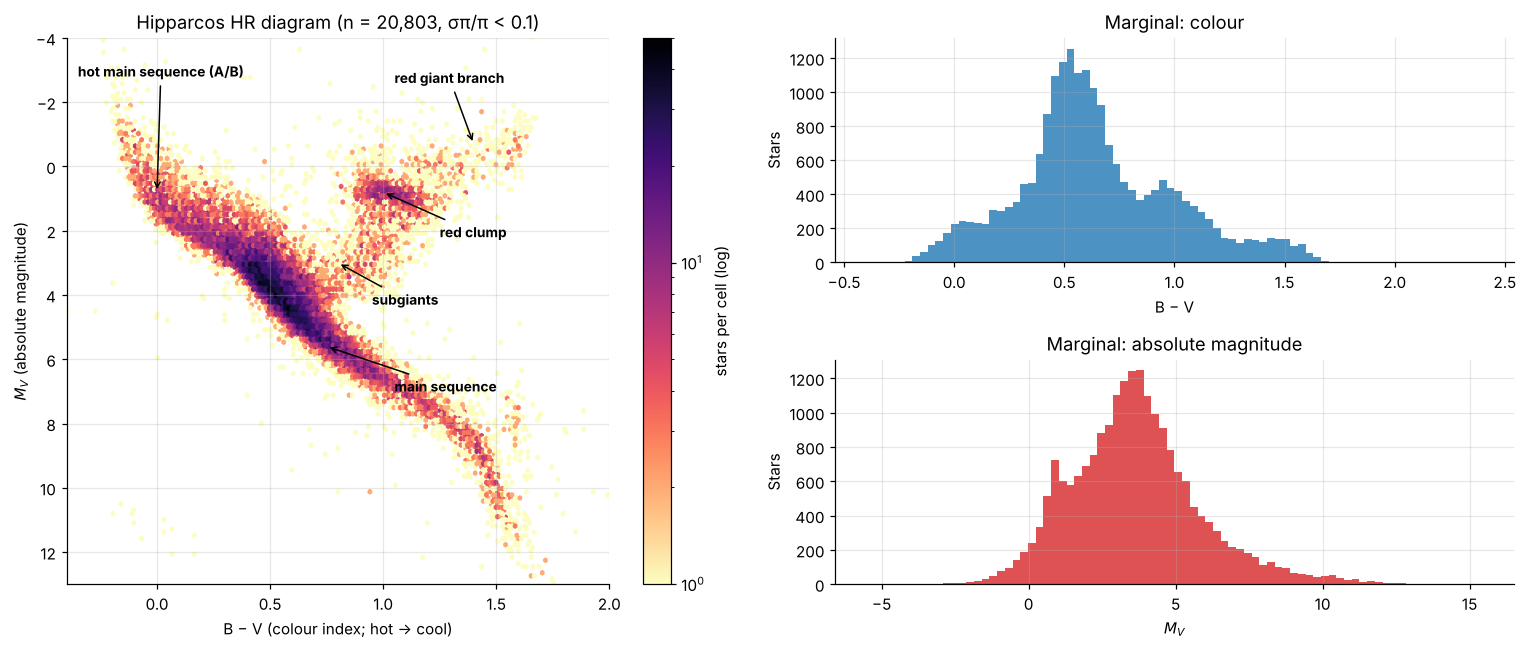

,mean,variance,skewness,excess kurtosis
B − V,0.6402,0.1281,0.4783,0.2813
M_V,3.6191,4.9321,0.5794,1.0290


In [3]:
fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(1, 2, 1)
hb = ax.hexbin(BV, MV, gridsize=170, bins="log", cmap="magma_r", extent=(-0.4, 2.0, -5, 14), mincnt=1)
plt.colorbar(hb, ax=ax, label="stars per cell (log)")
for label, xy, txt in [("main sequence", (0.75, 5.6), (1.05, 7.0)), ("red clump", (1.0, 0.8), (1.25, 2.2)),
                       ("red giant branch", (1.4, -0.7), (1.05, -2.6)), ("subgiants", (0.8, 3.0), (0.95, 4.3)),
                       ("hot main sequence (A/B)", (0.0, 0.8), (-0.35, -2.8))]:
    ax.annotate(label, xy, xytext=txt, fontsize=9, weight="bold", arrowprops=dict(arrowstyle="->", lw=1))
hr_axes(ax, f"Hipparcos HR diagram (n = {len(hip):,}, σπ/π < 0.1)"); ax.set_xlim(-0.4, 2.0); ax.set_ylim(13, -4)

ax1, ax2 = fig.add_subplot(2, 2, 2), fig.add_subplot(2, 2, 4)
ax1.hist(BV, bins=80, color="tab:blue", alpha=0.8); ax1.set(xlabel="B − V", ylabel="Stars", title="Marginal: colour")
ax2.hist(MV, bins=80, color="tab:red", alpha=0.8); ax2.set(xlabel="$M_V$", ylabel="Stars", title="Marginal: absolute magnitude")
plt.tight_layout(); save("t1_hr_diagram"); plt.show()

moments = pd.DataFrame({name: {"mean": s.mean(), "variance": s.var(), "skewness": s.skew(), "excess kurtosis": s.kurtosis()}
                        for name, s in [("B − V", hip["B-V"]), ("M_V", hip["MV"])]}).T
moments.round(4)

**Which distribution family?** A single Gaussian cannot describe a marginal that mixes several populations.
A 1-D **Gaussian mixture** is the natural family; BIC chooses the number of components.

In [4]:
rows = {}
for name, v in [("B − V", BV), ("M_V", MV)]:
    X1 = v.reshape(-1, 1)
    bics = {K: GaussianMixture(K, n_init=3, random_state=SEED).fit(X1).bic(X1) for K in range(1, 7)}
    best = min(bics, key=bics.get)
    g = GaussianMixture(best, n_init=3, random_state=SEED).fit(X1)
    order = np.argsort(g.means_.ravel())
    rows[name] = {"ΔBIC (K=1 vs best)": bics[1] - bics[best], "best K": best,
                  "component means": np.round(g.means_.ravel()[order], 2), "weights": np.round(g.weights_[order], 2)}
pd.DataFrame(rows).T

,ΔBIC (K=1 vs best),best K,component means,weights
B − V,2549.892355,4,"[0.16, 0.54, 0.94, 1.35]","[0.17, 0.52, 0.22, 0.09]"
M_V,1216.010475,3,"[1.5, 3.9, 6.77]","[0.32, 0.52, 0.17]"


**Interpretation**

* **Sample.** Of 118,184 catalogue rows, 20,803 stars (18%) survive the cuts. The parallax-quality cut removes most of them, because only nearby stars (≲ 100–200 pc) have parallaxes measured to 10%.
* **The HR diagram** shows the textbook structure. The **main sequence** runs diagonally from hot, luminous A/B stars (top left) to cool, faint K/M dwarfs (bottom right). The **red clump** sits at B − V ≈ 1.0, $M_V$ ≈ 0.8: core-helium-burning giants, which are numerous because the phase lasts ~100 Myr. The **red giant branch** rises from the subgiants towards the upper right. Very few white dwarfs survive the cut, as the brief expected.
* **Moments.** B − V: mean 0.64, skew 0.48. $M_V$: mean 3.62 mag, variance 4.93, skew 0.58, excess kurtosis 1.03. The moments alone hide the structure: neither marginal is unimodal.
* **Distribution family.** A **Gaussian mixture** describes both marginals far better than a single Gaussian (ΔBIC = 2,550 for colour, 1,216 for magnitude). Colour needs 4 components: hot MS stars (0.16), the F/G main-sequence peak (0.54), the red clump and giants (0.94), and the reddest stars (1.35). Magnitude needs 3: giants and bright stars (≈ 1.5), the main-sequence bulk (≈ 3.9), and faint K/M dwarfs (≈ 6.8). The multimodality is physical. Each mode is a stellar population at a different evolutionary stage, so forcing one Gaussian would average over unrelated groups.

## Task 2 — Solar-colour stars as a Gaussian

Slice $0.60 < B-V < 0.65$ (G-type, near-solar colour). Model $M_V \sim \mathcal N(\mu,\sigma^2)$.

$$\ell(\mu,\sigma^2) = -\frac n2\log(2\pi) - \frac n2\log\sigma^2 - \frac{1}{2\sigma^2}\sum_i (x_i-\mu)^2$$

* $\dfrac{\partial\ell}{\partial\mu} = \dfrac{1}{\sigma^2}\sum_i (x_i-\mu) = 0 \;\Rightarrow\; \hat\mu = \bar x$
* $\dfrac{\partial\ell}{\partial\sigma^2} = -\dfrac{n}{2\sigma^2} + \dfrac{1}{2\sigma^4}\sum_i (x_i-\mu)^2 = 0 \;\Rightarrow\; \hat\sigma^2 = \dfrac1n\sum_i (x_i-\bar x)^2$

**Bias.** Since $\sum_i (x_i-\bar x)^2 = \sum_i (x_i-\mu)^2 - n(\bar x-\mu)^2$, taking expectations gives $n\sigma^2 - n\cdot\sigma^2/n = (n-1)\sigma^2$.
Hence $\mathbb E[\hat\sigma^2] = \frac{n-1}{n}\sigma^2$ and $\operatorname{Bias}(\hat\sigma^2) = -\sigma^2/n$: dividing by $n$ instead of $n-1$ slightly underestimates the variance.

n = 1431
μ̂ = 4.2465 mag   σ̂²_MLE = 0.5140   σ̂ = 0.7170 mag   s² (n−1) = 0.5144
Estimated bias −σ²/n = -0.00036  (-0.070% of σ²)
Skewness = -1.925, excess kurtosis = 13.049; D'Agostino–Pearson normality p = 3.7e-155
Share of slice brighter than M_V = 3.5 (subgiant region): 13.8%


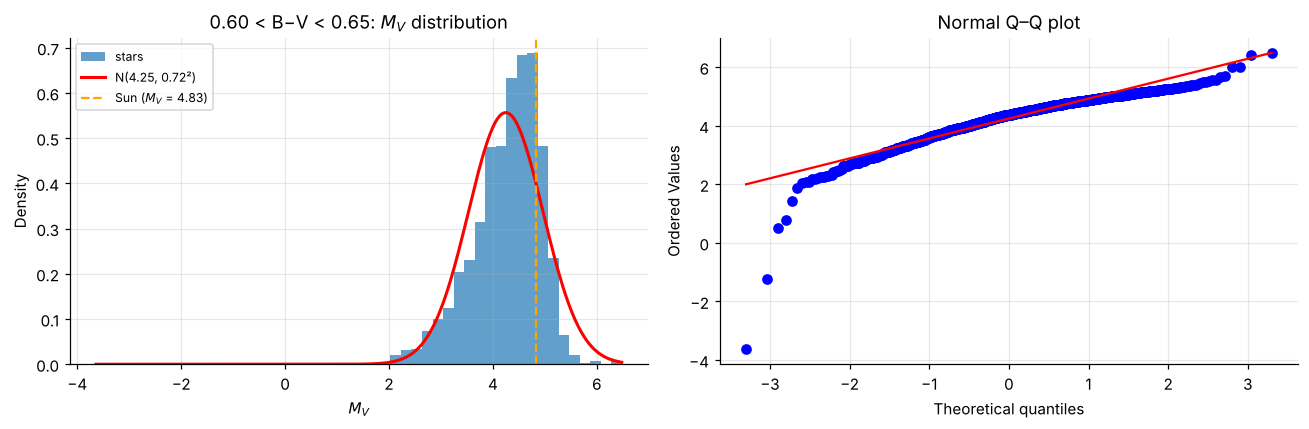

In [5]:
g_slice = hip[(hip["B-V"] > 0.60) & (hip["B-V"] < 0.65)]
x = g_slice["MV"].to_numpy(); n = len(x)
mu_hat = x.mean()
s2_mle = np.mean((x - mu_hat)**2)
s2_unb = x.var(ddof=1)
sigma_hat = np.sqrt(s2_mle)

print(f"n = {n}")
print(f"μ̂ = {mu_hat:.4f} mag   σ̂²_MLE = {s2_mle:.4f}   σ̂ = {sigma_hat:.4f} mag   s² (n−1) = {s2_unb:.4f}")
print(f"Estimated bias −σ²/n = {-s2_unb/n:.5f}  ({-1/n:.3%} of σ²)")
print(f"Skewness = {stats.skew(x):.3f}, excess kurtosis = {stats.kurtosis(x):.3f}; "
      f"D'Agostino–Pearson normality p = {stats.normaltest(x).pvalue:.1e}")
print(f"Share of slice brighter than M_V = 3.5 (subgiant region): {(x < 3.5).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(x, bins=50, density=True, alpha=0.7, label="stars")
grid = np.linspace(x.min(), x.max(), 400)
ax[0].plot(grid, stats.norm.pdf(grid, mu_hat, sigma_hat), "r", lw=2, label=f"N({mu_hat:.2f}, {sigma_hat:.2f}²)")
ax[0].axvline(M_SUN, color="orange", ls="--", label="Sun ($M_V$ = 4.83)")
ax[0].set(xlabel="$M_V$", ylabel="Density", title="0.60 < B−V < 0.65: $M_V$ distribution"); ax[0].legend(fontsize=8)
stats.probplot(x, dist="norm", plot=ax[1]); ax[1].set_title("Normal Q–Q plot")
plt.tight_layout(); save("t2_gaussian_slice"); plt.show()

**Interpretation**

* For the 1,431 solar-colour stars, **μ̂ = 4.25 mag and σ̂ = 0.72 mag**. The MLE variance (÷n) is 0.5140 against 0.5144 for the unbiased estimator (÷(n−1)). The bias, −σ²/n ≈ −0.0004 (0.07% of σ²), is negligible at this sample size.
* **The Gaussian assumption holds only in the core.** The Q–Q plot follows the line between about ±1.5σ but bends sharply at the bright end. Skewness is −1.9, excess kurtosis 13, and a normality test rejects decisively (p ≈ 10⁻¹⁵⁵). The bright tail is **subgiants** (13.8% of the slice is brighter than $M_V$ = 3.5): stars with the Sun's colour that have left the main sequence and expanded. A colour slice is a vertical cut through the HR diagram and does not isolate a single population.
* **Why the mean is brighter than the Sun (4.25 vs 4.83):** the subgiant tail pulls it up, and so do **Malmquist bias** and unresolved binaries. Hipparcos is magnitude-limited, so intrinsically brighter stars are visible to larger distances and are over-represented.

## Task 3 — Bayesian estimate of μ with the Sun as prior

Prior $\mu\sim\mathcal N(\mu_0,\tau^2)$ with $\mu_0 = 4.83$ (the Sun), $\tau^2 = 1$; $\sigma^2$ fixed at the Task 2 MLE.
The log posterior is quadratic in μ:

$$\log p(\mu\mid x) = -\frac{(\mu-\mu_0)^2}{2\tau^2} - \frac{\sum_i(x_i-\mu)^2}{2\sigma^2} + \text{const}
= -\frac12\Big(\frac1{\tau^2}+\frac n{\sigma^2}\Big)\mu^2 + \Big(\frac{\mu_0}{\tau^2}+\frac{n\bar x}{\sigma^2}\Big)\mu + \text{const},$$

so completing the square gives a Gaussian posterior $\mathcal N(\mu_n,\tau_n^2)$:

$$\frac1{\tau_n^2} = \frac1{\tau^2}+\frac n{\sigma^2}, \qquad \mu_n = \tau_n^2\Big(\frac{\mu_0}{\tau^2}+\frac{n\bar x}{\sigma^2}\Big) = w\,\mu_0 + (1-w)\,\bar x,\quad w = \frac{1/\tau^2}{1/\tau^2+n/\sigma^2}.$$

Precisions add, and the posterior mean is a precision-weighted average of the prior mean and the sample mean.
The prior counts as much as $n_0 = \sigma^2/\tau^2$ observations.

Prior N(4.83, 1) is worth n0 = σ²/τ² = 0.51 stars


,n,sample mean,posterior mean,posterior sd,prior weight w
n = 50,50.0,4.1782,4.1848,0.1009,0.0102
full slice (n = 1431),1431.0,4.2465,4.2467,0.0189,0.0004


Sensitivity — a confident prior N(4.83, 0.1²), worth n0 = σ²/0.01 = 51.4 stars:


,n,sample mean,posterior mean,posterior sd,prior weight w
n = 50,50.0,4.1782,4.5086,0.0712,0.5069
full slice (n = 1431),1431.0,4.2465,4.2667,0.0186,0.0347


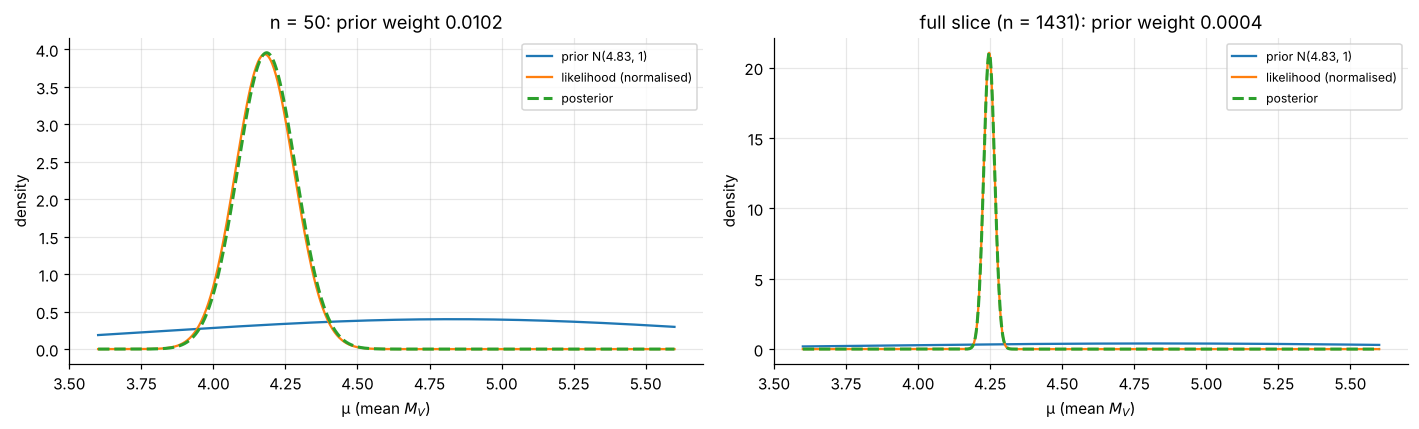

In [6]:
def posterior(sample, mu0=M_SUN, tau2=1.0, sigma2=s2_mle):
    m = len(sample); xb = sample.mean()
    tau_n2 = 1 / (1 / tau2 + m / sigma2)
    w = (1 / tau2) * tau_n2
    return {"n": m, "sample mean": xb, "posterior mean": tau_n2 * (mu0 / tau2 + m * xb / sigma2),
            "posterior sd": np.sqrt(tau_n2), "prior weight w": w}

rng = np.random.default_rng(SEED)
x50 = rng.choice(x, size=50, replace=False)
cases = {"n = 50": x50, f"full slice (n = {n})": x}
t3 = pd.DataFrame({k: posterior(v) for k, v in cases.items()}).T
t3_tight = pd.DataFrame({k: posterior(v, tau2=0.01) for k, v in cases.items()}).T
print(f"Prior N(4.83, 1) is worth n0 = σ²/τ² = {s2_mle:.2f} stars")
display(t3.round(4))
print("Sensitivity — a confident prior N(4.83, 0.1²), worth n0 = σ²/0.01 =", round(s2_mle / 0.01, 1), "stars:")
display(t3_tight.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (title, smp) in zip(ax, cases.items()):
    p = posterior(smp); m = len(smp)
    grid = np.linspace(3.6, 5.6, 1000)
    a.plot(grid, stats.norm.pdf(grid, M_SUN, 1.0), label="prior N(4.83, 1)")
    a.plot(grid, stats.norm.pdf(grid, smp.mean(), np.sqrt(s2_mle / m)), label="likelihood (normalised)")
    a.plot(grid, stats.norm.pdf(grid, p["posterior mean"], p["posterior sd"]), "--", lw=2, label="posterior")
    a.set(title=f"{title}: prior weight {p['prior weight w']:.4f}", xlabel="μ (mean $M_V$)", ylabel="density")
    a.legend(fontsize=8)
plt.tight_layout(); save("t3_bayesian"); plt.show()

**Interpretation**

* The prior N(4.83, 1) carries the information of only **n₀ = σ²/τ² ≈ 0.5 stars**, so the likelihood dominates even at n = 50. The prior weight is 1.0%, and the posterior mean (4.185) differs from the sample mean (4.178) by 0.007 mag. With all 1,431 stars the weight is 0.04%, and the posterior is the likelihood (4.2467 ± 0.019).
* **When would the prior matter?** The sensitivity check uses a confident prior, N(4.83, 0.1²), worth 51 stars. At n = 50 it then has about half the weight and pulls the estimate to 4.51, halfway between the Sun and the data. With 1,431 stars it still shifts the estimate by only 0.02 mag.
* **Astrophysically,** the Sun is a poor prior for the mean of this slice. The sample mean is 0.58 mag brighter for the selection reasons discussed in Task 2, and a strong prior would hide that real effect. A vague prior, as in the brief, lets the data speak.

## Task 4 — The main-sequence relation and how the sample is selected

The brief proposes the main-sequence (MS) selection $0.3 < B-V < 1.5$ and $M_V > 1.5 + 5(B-V)$, and asks to justify or refine it.
Checking where that line falls relative to the data shows it runs **along the ridge of the main sequence**: in each colour bin the most common $M_V$ sits on the line.
The cut therefore removes the brighter half of the main sequence.
Because the selection boundary is itself a line with slope 5, a regression on the selected stars partly recovers **the cut, not the stars**.

**Refinement:** move the boundary 1 mag brighter, to $M_V > 0.5 + 5(B-V)$. It then lies in the sparse gap between the main sequence and the subgiant / giant branches.
Both selections are compared below.

In [7]:
colour_ok = (hip["B-V"] > 0.3) & (hip["B-V"] < 1.5)
ms_orig = hip[colour_ok & (hip["MV"] > 1.5 + 5 * hip["B-V"])].reset_index(drop=True)
ms = hip[colour_ok & (hip["MV"] > 0.5 + 5 * hip["B-V"])].reset_index(drop=True)

# Where is the MS ridge relative to the brief's cut? (mode of M_V per colour bin)
ridge = []
for lo in np.arange(0.3, 1.5, 0.1):
    s = hip.loc[(hip["B-V"] >= lo) & (hip["B-V"] < lo + 0.1) & (hip["MV"] > 3 + 3 * (lo - 0.3)), "MV"]
    h, e = np.histogram(s, bins=np.arange(0, 12, 0.2))
    ridge.append({"B−V bin": f"{lo:.1f}–{lo+0.1:.1f}", "MS ridge (mode M_V)": e[h.argmax()] + 0.1,
                  "brief cut 1.5+5(B−V)": 1.5 + 5 * (lo + 0.05), "refined cut 0.5+5(B−V)": 0.5 + 5 * (lo + 0.05)})
print(f"Selected stars — brief cut: {len(ms_orig):,};  refined cut: {len(ms):,}")
pd.DataFrame(ridge).set_index("B−V bin").round(2).T

Selected stars — brief cut: 4,551;  refined cut: 12,337


B−V bin,0.3–0.4,0.4–0.5,0.5–0.6,0.6–0.7,0.7–0.8,0.8–0.9,0.9–1.0,1.0–1.1,1.1–1.2,1.2–1.3,1.3–1.4,1.4–1.5
MS ridge (mode M_V),3.10,3.50,4.10,4.70,5.30,5.90,6.30,6.70,7.10,7.50,8.30,9.10
brief cut 1.5+5(B−V),3.25,3.75,4.25,4.75,5.25,5.75,6.25,6.75,7.25,7.75,8.25,8.75
refined cut 0.5+5(B−V),2.25,2.75,3.25,3.75,4.25,4.75,5.25,5.75,6.25,6.75,7.25,7.75


In [8]:
def ols(xv, yv, degree=1):
    X = np.vander(xv, degree + 1, increasing=True)          # columns 1, x, x², ...
    beta = np.linalg.solve(X.T @ X, X.T @ yv)               # normal equations  XᵀX β = Xᵀy
    fitted = X @ beta; resid = yv - fitted
    m, p = X.shape
    rss = resid @ resid
    se = np.sqrt(np.diag(rss / (m - p) * np.linalg.inv(X.T @ X)))
    return dict(X=X, beta=beta, se=se, fitted=fitted, resid=resid, rss=rss, n=m, p=p,
                r2=1 - rss / np.sum((yv - yv.mean())**2))

xb, yb = ms["B-V"].to_numpy(), ms["MV"].to_numpy()
fit1 = ols(xb, yb)
print("Design matrix X (first five rows) and response y:")
display(pd.DataFrame(np.column_stack([fit1["X"][:5], yb[:5]]), columns=["intercept", "B−V", "y = M_V"]))

fit_o = ols(ms_orig["B-V"].to_numpy(), ms_orig["MV"].to_numpy())
t4 = pd.DataFrame({
    "brief cut": {"n": fit_o["n"], "intercept": fit_o["beta"][0], "se(intercept)": fit_o["se"][0],
                  "slope": fit_o["beta"][1], "se(slope)": fit_o["se"][1], "R²": fit_o["r2"],
                  "residual sd": np.sqrt(fit_o["rss"] / (fit_o["n"] - 2))},
    "refined cut": {"n": fit1["n"], "intercept": fit1["beta"][0], "se(intercept)": fit1["se"][0],
                    "slope": fit1["beta"][1], "se(slope)": fit1["se"][1], "R²": fit1["r2"],
                    "residual sd": np.sqrt(fit1["rss"] / (fit1["n"] - 2))}}).T
t4.round(4)

Design matrix X (first five rows) and response y:


,intercept,B−V,y = M_V
0,1.0,0.740,5.884768
1,1.0,0.516,3.669061
2,1.0,0.456,3.003578
3,1.0,0.778,5.536531
4,1.0,1.150,7.721394


,n,intercept,se(intercept),slope,se(slope),R²,residual sd
brief cut,4551.0,1.5919,0.0172,5.2959,0.0207,0.9350,0.3785
refined cut,12337.0,0.8949,0.0110,5.6860,0.0152,0.9189,0.4437


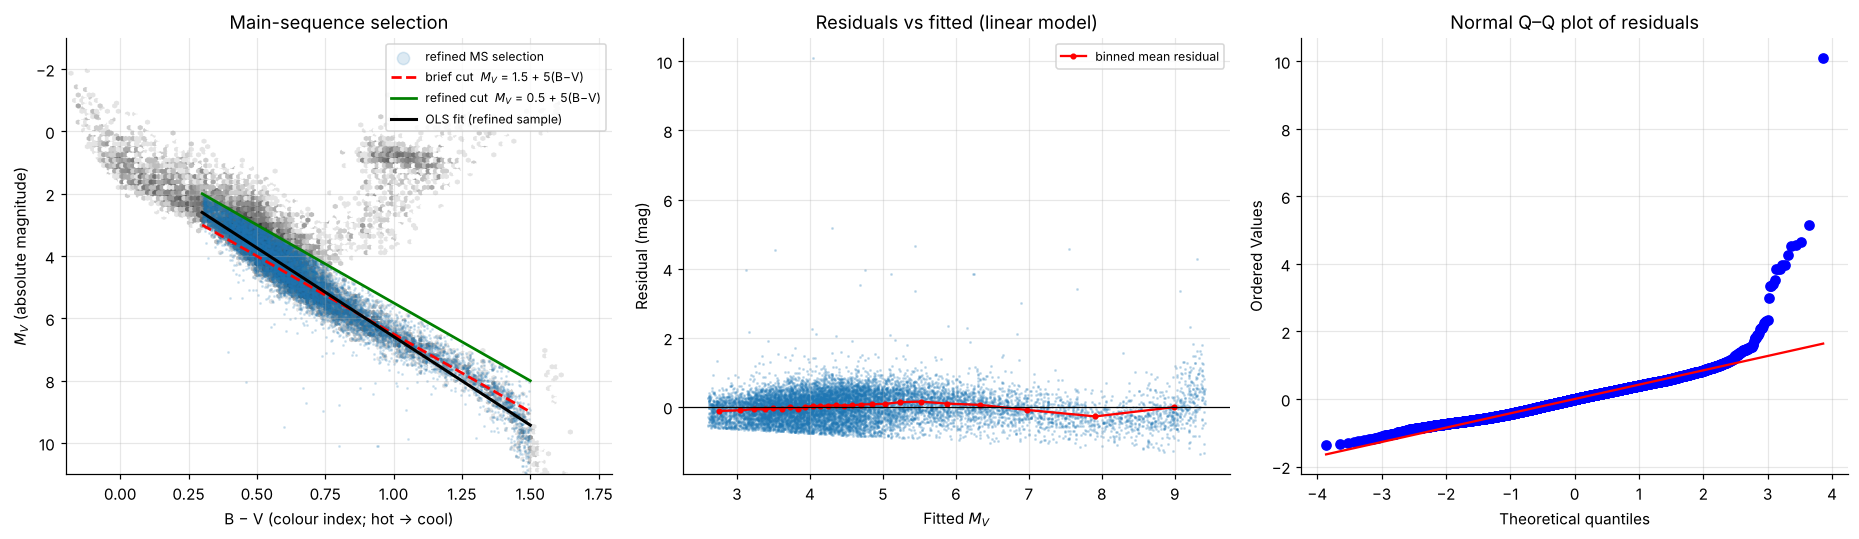

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].hexbin(BV, MV, gridsize=150, bins="log", cmap="Greys", extent=(-0.2, 1.8, -3, 12), mincnt=1)
ax[0].scatter(xb, yb, s=1, alpha=0.15, color="tab:blue", label="refined MS selection")
xx = np.linspace(0.3, 1.5, 50)
ax[0].plot(xx, 1.5 + 5 * xx, "r--", lw=1.8, label="brief cut  $M_V$ = 1.5 + 5(B−V)")
ax[0].plot(xx, 0.5 + 5 * xx, "g-", lw=1.8, label="refined cut  $M_V$ = 0.5 + 5(B−V)")
ax[0].plot(xx, fit1["beta"][0] + fit1["beta"][1] * xx, "k", lw=2, label="OLS fit (refined sample)")
hr_axes(ax[0], "Main-sequence selection"); ax[0].set_xlim(-0.2, 1.8); ax[0].set_ylim(11, -3)
ax[0].legend(fontsize=8, loc="upper right", markerscale=8)

ax[1].scatter(fit1["fitted"], fit1["resid"], s=1, alpha=0.2)
order = np.argsort(xb); bins_ = np.array_split(order, 25)
ax[1].plot([fit1["fitted"][b].mean() for b in bins_], [fit1["resid"][b].mean() for b in bins_], "r-o", ms=3,
           label="binned mean residual")
ax[1].axhline(0, color="k", lw=0.8); ax[1].legend(fontsize=8)
ax[1].set(title="Residuals vs fitted (linear model)", xlabel="Fitted $M_V$", ylabel="Residual (mag)")
stats.probplot(fit1["resid"], dist="norm", plot=ax[2]); ax[2].set_title("Normal Q–Q plot of residuals")
plt.tight_layout(); save("t4_main_sequence"); plt.show()

**Interpretation**

* **The brief's selection removes half the main sequence.** In every colour bin, the most common $M_V$ (the MS ridge) lies within ±0.3 mag of the line $1.5 + 5(B-V)$. Only stars *fainter* than the ridge survive (4,551 stars). The fitted slope, 5.30, is close to the cut's own slope of 5: the regression partly recovers the selection boundary.
* **The refined cut** $M_V > 0.5 + 5(B-V)$ lies in the sparse gap between the main sequence and the subgiant / giant branches. It keeps 12,337 stars, i.e. the full width of the main sequence. The fit becomes
  **$M_V = 0.895\,(\pm 0.011) + 5.686\,(\pm 0.015)\,(B-V)$, with R² = 0.919** and residual sd 0.44 mag.
  The slope is 7% steeper than with the brief's cut. R² is a little lower because the sample now includes the natural width of the main sequence (different ages and metallicities, unresolved binaries), which a truncated sample hides.
* **Interpretation of the slope:** reddening by 0.1 in B − V (a cooler star) makes a main-sequence star ≈ 0.57 mag fainter, about 1.7× less luminous.
* **Is a straight line adequate?** Not quite. The binned residuals show a systematic S-shaped pattern: the line is too faint at the blue end, too bright in the middle, and drifts again at the red end. The Q–Q plot has a heavy right tail from 25 stars lying 2–10 mag below the line (white dwarfs and probably bad measurements). Systematic curvature in the residuals motivates the cubic model of Task 7.

## Task 5 — Classifying giants vs main-sequence stars from colour and apparent magnitude

Label: giant ($M_V < 2$, $Y=1$) vs main sequence ($Y=0$, the refined Task 4 selection).
Both classes are restricted to the same colour window $0.3 < B-V < 1.5$. Bluer stars with $M_V < 2$ are hot **main-sequence** B/A stars, not giants, so counting them as giants would mislabel the data.

Predictors are **B − V and apparent magnitude V only**. $M_V$ defines the label, and the parallax is used to compute $M_V$.

**Loss.** With $p_i = \sigma(\beta_0 + \beta_1 (B-V)_i + \beta_2 V_i)$ and $Y_i\sim\text{Bernoulli}(p_i)$, the negative log-likelihood is the cross-entropy;
L2 adds $\frac1{2C}\lVert\beta\rVert^2$:
$\ \mathcal L = -\sum_i [y_i\log p_i + (1-y_i)\log(1-p_i)] + \frac{1}{2C}\sum_j\beta_j^2.$

In [10]:
giants_all = hip[hip["MV"] < 2]
giants = giants_all[(giants_all["B-V"] > 0.3) & (giants_all["B-V"] < 1.5)]
cls = pd.concat([giants.assign(Y=1), ms.assign(Y=0)], ignore_index=True)
print(f"M_V < 2: {len(giants_all):,} stars, of which {len(giants_all) - len(giants):,} are outside 0.3 < B−V < 1.5 (mostly hot MS stars) and excluded")
print(f"Classification sample: {len(giants):,} giants + {len(ms):,} main-sequence = {len(cls):,}  (giant share {cls['Y'].mean():.1%})")

X_c, y_c = cls[["B-V", "Vmag"]], cls["Y"].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(X_c, y_c, test_size=0.25, stratify=y_c, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
Cs = np.logspace(-4, 3, 22)
clf = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=Cs, cv=cv, l1_ratios=(0.0,), scoring="neg_log_loss", max_iter=5000))
clf.fit(X_tr, y_tr)
lr = clf[-1]; best_C = float(lr.C_[0])
print(f"Best C = {best_C:.4g}")
pd.Series({"intercept": lr.intercept_[0], "B−V (per sd)": lr.coef_[0][0], "V (per sd)": lr.coef_[0][1]},
          name="standardised coefficient").round(3).to_frame()

M_V < 2: 4,744 stars, of which 2,328 are outside 0.3 < B−V < 1.5 (mostly hot MS stars) and excluded
Classification sample: 2,416 giants + 12,337 main-sequence = 14,753  (giant share 16.4%)


Best C = 2.154


,standardised coefficient
intercept,-2.988
B−V (per sd),1.480
V (per sd),-2.646


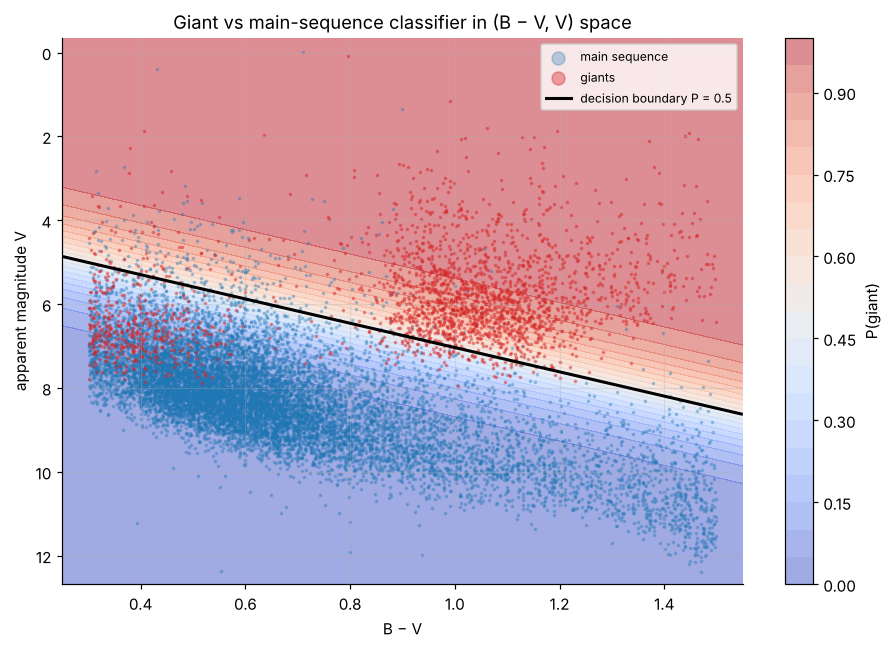

In [11]:
gx, gy = np.meshgrid(np.linspace(0.25, 1.55, 300), np.linspace(X_c["Vmag"].min() - 0.3, X_c["Vmag"].max() + 0.3, 300))
proba = clf.predict_proba(pd.DataFrame({"B-V": gx.ravel(), "Vmag": gy.ravel()}))[:, 1].reshape(gx.shape)

plt.figure(figsize=(8.5, 6))
cf = plt.contourf(gx, gy, proba, levels=20, cmap="coolwarm", alpha=0.5)
plt.colorbar(cf, label="P(giant)")
plt.contour(gx, gy, proba, levels=[0.5], colors="k", linewidths=2)
plt.scatter(ms["B-V"], ms["Vmag"], s=2, alpha=0.3, color="tab:blue", label="main sequence")
plt.scatter(giants["B-V"], giants["Vmag"], s=2, alpha=0.4, color="tab:red", label="giants")
plt.plot([], [], "k", lw=2, label="decision boundary P = 0.5")
plt.gca().invert_yaxis(); plt.xlabel("B − V"); plt.ylabel("apparent magnitude V")
plt.title("Giant vs main-sequence classifier in (B − V, V) space"); plt.legend(markerscale=6, fontsize=8)
plt.tight_layout(); save("t5_decision_boundary"); plt.show()

**Interpretation**

* **Sample.** 2,416 giants and 12,337 main-sequence stars (16% giants). 2,328 stars with $M_V$ < 2 are bluer than B − V = 0.3. They are hot main-sequence stars (A/B type) and were excluded rather than labelled as giants.
* **Coefficients (per standard deviation):** V = **−2.65**, B − V = **+1.48**. The cross-validated C = 2.15 means almost no regularisation is needed: the model has only two features, far fewer than the ~11,000 training stars.
  * *Redder → giant:* within this colour window, giants are mostly red-clump and RGB stars (B − V ≈ 1.0), while the main sequence spreads over all colours.
  * *Apparently brighter → giant:* this is a **selection effect**. The 10% parallax cut requires π ≳ 10 × σπ ≈ 10 mas, so most stars lie within ~100–200 pc. Inside that volume a giant ($M_V$ ≈ 1) appears at V ≈ 5–7, while a G/K dwarf ($M_V$ ≈ 5–7) appears at V ≈ 8–11. The apparent magnitude therefore acts as a stand-in for luminosity *because* the sample is distance-limited. The same classifier would not work in a deep survey where giants are seen to kiloparsecs.
* **The decision boundary** is a line in (B − V, V): for redder stars, a fainter V still counts as "giant". The hard cases are 436 "giants" with B − V < 0.5. They are slightly evolved F stars just above $M_V$ = 2, which overlap the bright edge of the main sequence in this plane.

## Task 6 — Evaluation for a standard-candle application

**Which error matters more?** Red-clump giants are used as *standard candles*: their nearly constant luminosity converts apparent magnitude into distance.
A **false positive**, i.e. a dwarf classified as a giant, is assigned a luminosity ~5 mag (≈100×) too high, so its inferred distance is ~10× too large.
A few such contaminants bias the calibration far more than the loss of a few genuine giants (**false negatives**), which only reduces the sample size.
So **precision on the giant class is the priority**.
Two precision-oriented operating points are chosen on **out-of-fold training predictions** and only then applied to the test set:
the threshold that maximises $F_{0.5}$ (precision weighted twice as much as recall), and the lowest threshold that reaches **95% precision**, a target purity for a calibration sample.

In [12]:
p_te = clf.predict_proba(X_te)[:, 1]
oof = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=5000)),
                        X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
f05 = [fbeta_score(y_tr, (oof >= t).astype(int), beta=0.5) for t in ths]
t_star = ths[int(np.argmax(f05))]
prec_oof = np.array([precision_score(y_tr, (oof >= t).astype(int), zero_division=0) for t in ths])
t_p95 = ths[np.argmax(prec_oof >= 0.95)]

def evaluate(t):
    pr = (p_te >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pr).ravel()
    return {"precision": precision_score(y_te, pr), "recall": recall_score(y_te, pr), "F1": f1_score(y_te, pr),
            "F0.5": fbeta_score(y_te, pr, beta=0.5), "TN": tn, "FP": fp, "FN": fn, "TP": tp}

print(f"Test set: {len(y_te):,} stars;  AUC-ROC = {roc_auc_score(y_te, p_te):.4f};  "
      f"AUC-PR = {average_precision_score(y_te, p_te):.4f};  cross-entropy = {log_loss(y_te, p_te):.4f}")
print(f"Thresholds from training out-of-fold predictions: F0.5-optimal {t_star:.2f}; 95%-precision {t_p95:.2f}")
t6 = pd.DataFrame({"threshold 0.50": evaluate(0.5), f"threshold {t_star:.2f} (F0.5-optimal)": evaluate(t_star),
                   f"threshold {t_p95:.2f} (95% precision target)": evaluate(t_p95)}).T
print(f"Confusion matrix at the 95%-precision threshold ({t_p95:.2f}):")
display(pd.DataFrame(confusion_matrix(y_te, (p_te >= t_p95).astype(int)),
                     index=["actual: main sequence", "actual: giant"], columns=["pred: main sequence", "pred: giant"]))
t6.round(4)

Test set: 3,689 stars;  AUC-ROC = 0.9610;  AUC-PR = 0.8841;  cross-entropy = 0.1618
Thresholds from training out-of-fold predictions: F0.5-optimal 0.52; 95%-precision 0.92
Confusion matrix at the 95%-precision threshold (0.92):


,pred: main sequence,pred: giant
actual: main sequence,3075,10
actual: giant,370,234


,precision,recall,F1,F0.5,TN,FP,FN,TP
threshold 0.50,0.9019,0.7765,0.8345,0.8737,3034.0,51.0,135.0,469.0
threshold 0.52 (F0.5-optimal),0.9043,0.7666,0.8297,0.8729,3036.0,49.0,141.0,463.0
threshold 0.92 (95% precision target),0.9590,0.3874,0.5519,0.7405,3075.0,10.0,370.0,234.0


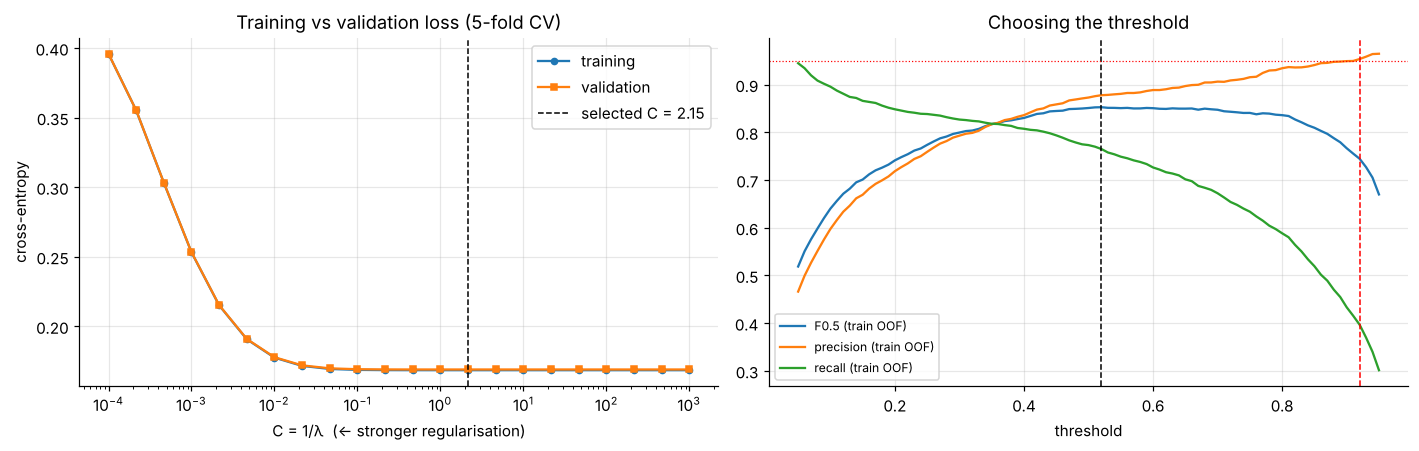

In [13]:
# Training vs validation cross-entropy across the regularisation path (averaged over the 5 folds)
tr_loss, va_loss = [], []
Xtr_np = X_tr.to_numpy()
for C in Cs:
    t_l, v_l = [], []
    for i_tr, i_va in cv.split(Xtr_np, y_tr):
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)).fit(X_tr.iloc[i_tr], y_tr[i_tr])
        t_l.append(log_loss(y_tr[i_tr], m.predict_proba(X_tr.iloc[i_tr])[:, 1]))
        v_l.append(log_loss(y_tr[i_va], m.predict_proba(X_tr.iloc[i_va])[:, 1]))
    tr_loss.append(np.mean(t_l)); va_loss.append(np.mean(v_l))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].semilogx(Cs, tr_loss, "o-", ms=4, label="training"); ax[0].semilogx(Cs, va_loss, "s-", ms=4, label="validation")
ax[0].axvline(best_C, color="k", ls="--", lw=1, label=f"selected C = {best_C:.3g}")
ax[0].set(xlabel="C = 1/λ  (← stronger regularisation)", ylabel="cross-entropy", title="Training vs validation loss (5-fold CV)")
ax[0].legend()
ax[1].plot(ths, f05, label="F0.5 (train OOF)")
ax[1].plot(ths, prec_oof, label="precision (train OOF)")
ax[1].plot(ths, [recall_score(y_tr, (oof >= t).astype(int)) for t in ths], label="recall (train OOF)")
ax[1].axvline(t_star, color="k", ls="--", lw=1); ax[1].axvline(t_p95, color="r", ls="--", lw=1)
ax[1].axhline(0.95, color="r", ls=":", lw=0.8); ax[1].set(xlabel="threshold", title="Choosing the threshold"); ax[1].legend(fontsize=8)
plt.tight_layout(); save("t6_evaluation"); plt.show()

**Interpretation**

* **Overall discrimination is strong.** On 3,689 test stars, AUC-ROC = 0.961 and AUC-PR = 0.884, against a 16% no-skill baseline. At threshold 0.5: precision 0.90, recall 0.78, F1 0.83 (51 false positives, 135 false negatives).
* **The F0.5-optimal threshold is 0.52.** It barely differs from 0.5, because the model is already precision-leaning at the default (precision 0.90 against recall 0.78).
* **A 95%-precision calibration sample requires threshold 0.92.** On the test set this gives **precision 0.959 with only 10 dwarfs among 244 selected giants** (FP down 80%), but recall falls to 0.39 and F1 to 0.55. For standard-candle work this is the right trade-off. Every contaminating dwarf would be placed ~10× too far away, while a smaller but clean giant sample still calibrates the distance scale.
* **Loss curves.** Training and validation cross-entropy are virtually identical across the whole regularisation path. With two features the model cannot overfit; it can only *underfit* when C ≲ 0.01 shrinks the coefficients towards zero. Any C ≳ 0.05 gives the same model, so the chosen C = 2.15 makes no practical difference.

## Task 7 — Is the main sequence a straight line? AIC vs BIC

* **M1:** $M_V = \beta_0 + \beta_1 (B-V) + \varepsilon$  (Task 4)
* **M2:** $M_V = \beta_0 + \beta_1 (B-V) + \beta_2 (B-V)^2 + \beta_3 (B-V)^3 + \varepsilon$

With Gaussian errors, maximising over $\sigma^2$ gives $\hat\sigma^2 = \text{RSS}/n$ and
$\hat\ell = -\frac n2\left[\log(2\pi) + \log(\text{RSS}/n) + 1\right]$.

* **AIC** $= 2k - 2\hat\ell$ estimates the expected out-of-sample Kullback–Leibler loss; $2k$ corrects the optimism of the in-sample fit.
* **BIC** $= k\log n - 2\hat\ell$ comes from a Laplace approximation of the marginal likelihood $p(\text{data}\mid M)$.

$k$ counts every estimated parameter, **including σ²**: $k=3$ for M1 and $k=5$ for M2.

n = 12,337;  BIC penalty per parameter log(n) = 9.42 vs 2 for AIC
Cubic coefficients: [-0.4005 10.6295 -5.636   1.9477]


,k,RSS,logL,AIC,BIC
M1 linear,3.0,2428.64,-7479.95,14965.89,14988.16
M2 cubic,5.0,2359.39,-7301.52,14613.03,14650.14
Δ (M2 − M1),2.0,-69.24,178.43,-352.86,-338.02


Local slope dM_V/d(B−V) of the cubic: B−V=0.4: 7.06, B−V=0.6: 5.97, B−V=0.8: 5.35, B−V=1.0: 5.20, B−V=1.2: 5.52, B−V=1.4: 6.30


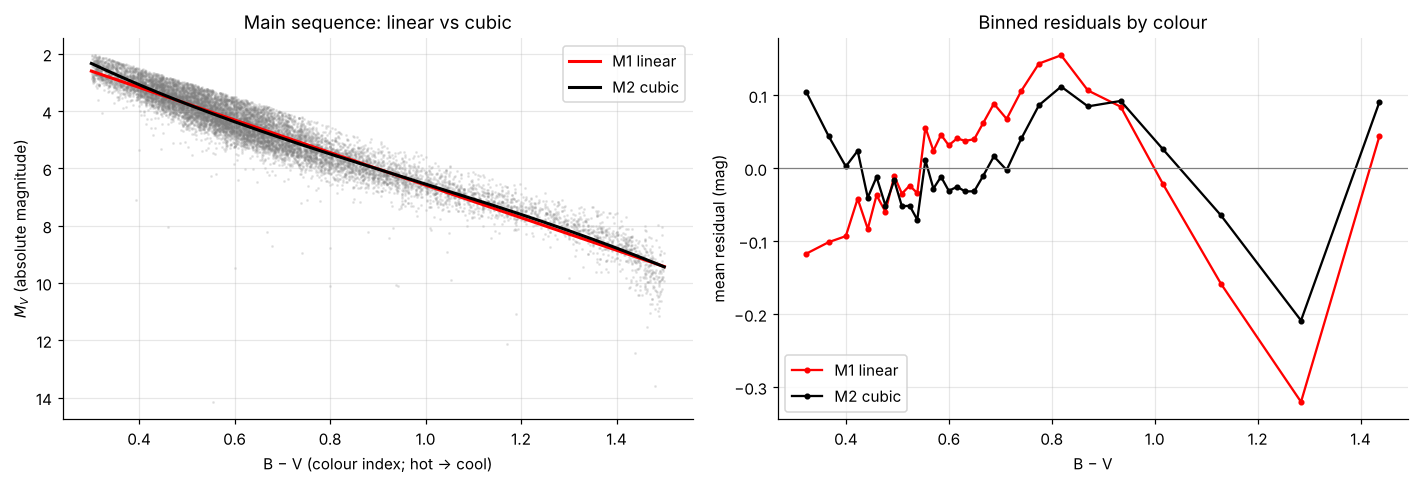

In [14]:
def ic(f):
    k = f["p"] + 1; m = f["n"]
    ll = -m / 2 * (np.log(2 * np.pi) + np.log(f["rss"] / m) + 1)
    return {"k": k, "RSS": f["rss"], "logL": ll, "AIC": 2 * k - 2 * ll, "BIC": k * np.log(m) - 2 * ll}

fit3 = ols(xb, yb, degree=3)
t7 = pd.DataFrame({"M1 linear": ic(fit1), "M2 cubic": ic(fit3)}).T
t7.loc["Δ (M2 − M1)"] = t7.loc["M2 cubic"] - t7.loc["M1 linear"]
print(f"n = {fit1['n']:,};  BIC penalty per parameter log(n) = {np.log(fit1['n']):.2f} vs 2 for AIC")
print("Cubic coefficients:", np.round(fit3["beta"], 4))
display(t7.round(2))

slope_at = lambda c: fit3["beta"][1] + 2 * fit3["beta"][2] * c + 3 * fit3["beta"][3] * c**2
print("Local slope dM_V/d(B−V) of the cubic:",
      ", ".join(f"B−V={c}: {slope_at(c):.2f}" for c in (0.4, 0.6, 0.8, 1.0, 1.2, 1.4)))

xx = np.linspace(0.3, 1.5, 200)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(xb, yb, s=1, alpha=0.15, color="gray")
ax[0].plot(xx, np.vander(xx, 2, increasing=True) @ fit1["beta"], "r", lw=2, label="M1 linear")
ax[0].plot(xx, np.vander(xx, 4, increasing=True) @ fit3["beta"], "k", lw=2, label="M2 cubic")
hr_axes(ax[0], "Main sequence: linear vs cubic"); ax[0].legend()
for f_, lab, c in [(fit1, "M1 linear", "r"), (fit3, "M2 cubic", "k")]:
    o = np.argsort(xb); b = np.array_split(o, 30)
    ax[1].plot([xb[i].mean() for i in b], [f_["resid"][i].mean() for i in b], "o-", color=c, ms=3, label=lab)
ax[1].axhline(0, color="gray", lw=0.8)
ax[1].set(xlabel="B − V", ylabel="mean residual (mag)", title="Binned residuals by colour"); ax[1].legend()
plt.tight_layout(); save("t7_linear_vs_cubic"); plt.show()

**Interpretation**

* **Both criteria choose the cubic, by a wide margin:** ΔAIC = −352.9 and ΔBIC = −338.0. The two extra coefficients reduce RSS by 69 (−2.9%), which is worth 357 units of −2ℓ against penalties of 4 (AIC) or 2·log(12,337) = 18.8 (BIC). BIC penalises 4.7× more per parameter but still agrees.
* **How good is the straight line?** A line explains 92% of the variance and is off by at most ~0.1–0.2 mag in mean residual, which is useful as a first approximation. The binned residuals, however, show systematic curvature that the cubic removes.
* **Physics of the curvature.** The cubic's local slope $dM_V/d(B-V)$ is **7.1 at B − V = 0.4, falls to 5.2 at 1.0 and rises again to 6.3 at 1.4**.
  * *Blue end (F stars):* luminosity rises steeply with mass ($L\propto M^{\sim4}$) while colour changes only slowly with temperature, so a small colour step means a large magnitude step.
  * *Middle (G–K):* the mass–luminosity relation flattens for lower masses ($L\propto M^{\sim2.5}$), so the main sequence is shallower.
  * *Red end (late K / M dwarfs):* B − V saturates, because molecular absorption makes the colour stop tracking temperature, while luminosity keeps falling. The slope steepens again.
  The main sequence is a mass sequence, and its curvature reflects the mass-dependent slope of the mass–luminosity relation together with the non-linear colour–temperature relation.

## Task 8 — Stellar populations with a Gaussian mixture model

GMM on $(B-V, M_V)$ for the full cleaned sample, with diagonal covariances $\Sigma_k=\operatorname{diag}(\sigma_{k,1}^2,\sigma_{k,2}^2)$, fitted by EM:

* **E-step:** $r_{ik} = \dfrac{\pi_k\,\mathcal N(x_i\mid\mu_k,\Sigma_k)}{\sum_{j=1}^K\pi_j\,\mathcal N(x_i\mid\mu_j,\Sigma_j)}$
* **M-step:** $N_k=\sum_i r_{ik}$, $\ \pi_k = N_k/n$, $\ \mu_k=\frac1{N_k}\sum_i r_{ik}x_i$, $\ \sigma_{k,d}^2=\frac1{N_k}\sum_i r_{ik}(x_{i,d}-\mu_{k,d})^2$

The brief asks for diagonal covariances and $K\in\{1,2,3,4\}$. BIC is still decreasing at K = 4, the edge of that grid, so two checks are added:
the grid is extended to K = 10, and **full** covariance matrices are compared, since the main sequence and giant branch are *tilted* in the colour–magnitude plane and an axis-aligned (diagonal) Gaussian cannot follow a tilted population.

In [15]:
Xg = hip[["B-V", "MV"]].to_numpy()
Ks = range(1, 11)
fits = {cov: {K: GaussianMixture(K, covariance_type=cov, n_init=5, random_state=SEED).fit(Xg) for K in Ks}
        for cov in ("diag", "full")}
bic = pd.DataFrame({cov: {K: g.bic(Xg) for K, g in f.items()} for cov, f in fits.items()})
K_brief = int(bic["diag"].loc[1:4].idxmin())
K_full = int(bic["full"].idxmin())
print(f"Diagonal, K in 1..4 (brief): best K = {K_brief}.  Diagonal, K in 1..10: best K = {int(bic['diag'].idxmin())} (still falling).")
print(f"Full covariance, K in 1..10: best K = {K_full}.  At K = 4, full beats diagonal by ΔBIC = {bic.loc[4, 'diag'] - bic.loc[4, 'full']:,.0f}")
display(bic.round(0).T)

def describe_components(g):
    lab = g.predict(Xg)
    sd = np.sqrt(g.covariances_ if g.covariance_type == "diag" else np.diagonal(g.covariances_, axis1=1, axis2=2))
    out = pd.DataFrame({"weight": g.weights_, "mean B−V": g.means_[:, 0], "mean M_V": g.means_[:, 1],
                        "sd B−V": sd[:, 0], "sd M_V": sd[:, 1], "stars": np.bincount(lab, minlength=g.n_components)})
    return out.sort_values("mean M_V").round(3), lab

g4, gF = fits["diag"][K_brief], fits["full"][K_full]
comp4, lab4 = describe_components(g4)
compF, labF = describe_components(gF)
print(f"Diagonal GMM, K = {K_brief}:"); display(comp4)
print(f"Full-covariance GMM, K = {K_full}:"); display(compF)

Diagonal, K in 1..4 (brief): best K = 4.  Diagonal, K in 1..10: best K = 10 (still falling).
Full covariance, K in 1..10: best K = 9.  At K = 4, full beats diagonal by ΔBIC = 16,587


,1,2,3,4,5,6,7,8,9,10
diag,108566.0,99985.0,89571.0,83182.0,79041.0,76099.0,74160.0,75462.0,69514.0,68643.0
full,102055.0,71856.0,68017.0,66595.0,65160.0,64709.0,63099.0,62987.0,61972.0,62017.0


Diagonal GMM, K = 4:


,weight,mean B−V,mean M_V,sd B−V,sd M_V,stars
3,0.313,0.535,1.333,0.463,1.093,6329
1,0.329,0.493,3.390,0.087,0.608,7047
0,0.242,0.706,4.903,0.100,0.703,5039
2,0.116,1.206,7.766,0.254,1.530,2388


Full-covariance GMM, K = 9:


,weight,mean B−V,mean M_V,sd B−V,sd M_V,stars
5,0.025,1.284,0.131,0.215,0.779,371
8,0.077,0.062,0.994,0.118,1.038,1895
1,0.088,1.023,1.240,0.101,0.893,2012
7,0.154,0.424,2.298,0.223,0.858,2537
3,0.223,0.500,3.355,0.138,0.691,5108
0,0.227,0.581,4.364,0.114,0.746,5142
4,0.022,0.921,4.703,0.576,4.246,270
6,0.152,0.908,6.128,0.221,1.066,2744
2,0.033,1.448,9.386,0.090,1.210,724


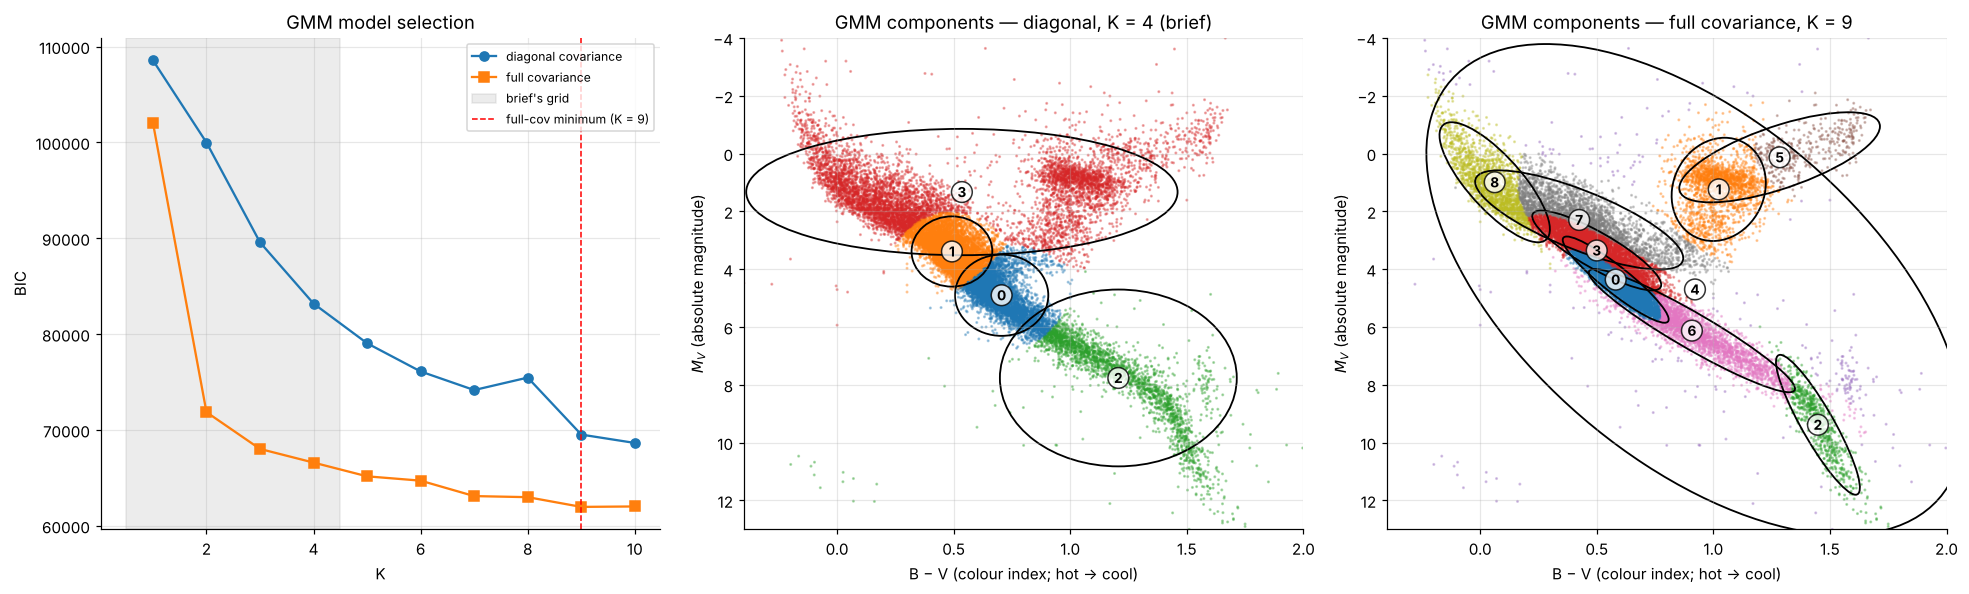

In [16]:
from matplotlib.patches import Ellipse
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
ax[0].plot(bic.index, bic["diag"], "o-", label="diagonal covariance")
ax[0].plot(bic.index, bic["full"], "s-", label="full covariance")
ax[0].axvspan(0.5, 4.5, color="gray", alpha=0.15, label="brief's grid")
ax[0].axvline(K_full, color="r", ls="--", lw=1, label=f"full-cov minimum (K = {K_full})")
ax[0].set(xlabel="K", ylabel="BIC", title="GMM model selection"); ax[0].legend(fontsize=8)
for a, g, lab, title in [(ax[1], g4, lab4, f"diagonal, K = {K_brief} (brief)"), (ax[2], gF, labF, f"full covariance, K = {K_full}")]:
    a.scatter(Xg[:, 0], Xg[:, 1], c=lab, cmap="tab10", s=1, alpha=0.35, vmin=0, vmax=9)
    for k in range(g.n_components):
        cov = np.diag(g.covariances_[k]) if g.covariance_type == "diag" else g.covariances_[k]
        vals, vecs = np.linalg.eigh(cov)
        angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
        a.add_patch(Ellipse(g.means_[k], 2 * 2 * np.sqrt(vals[1]), 2 * 2 * np.sqrt(vals[0]), angle=angle,
                            fill=False, color="k", lw=1.2))
        a.annotate(str(k), g.means_[k], ha="center", va="center", weight="bold", fontsize=9,
                   bbox=dict(boxstyle="circle,pad=0.15", fc="white", alpha=0.8))
    hr_axes(a, f"GMM components — {title}"); a.set_xlim(-0.4, 2.0); a.set_ylim(13, -4)
plt.tight_layout(); save("t8_gmm_populations"); plt.show()

**Interpretation**

* **Within the brief's grid (diagonal, K ≤ 4), BIC picks K = 4**, but BIC is still falling steeply there and keeps falling up to K = 10. That pattern signals a **misspecified model**, not more populations. The main sequence and the giant branch run diagonally across the colour–magnitude plane, and axis-aligned (diagonal) Gaussians can only tile a tilted band with many pieces.
* **Diagonal K = 4 components:** (0) G dwarfs at B − V 0.71, $M_V$ 4.9; (1) F dwarfs and turn-off stars at 0.49, 3.4; (2) K/M dwarfs at 1.21, 7.8; and (3) a single broad "bright stars" component (0.54, 1.3) that lumps **hot A/B main-sequence stars together with red-clump and RGB giants**. Physically that last component is two unrelated populations.
* **Full covariance fits much better** (ΔBIC = 16,600 at K = 4) and has a genuine BIC minimum at **K = 9**. Its components map onto physical populations:

| component | mean B − V | mean $M_V$ | population |
|---|---|---|---|
| 8 | 0.06 | 1.0 | hot main sequence (A stars) |
| 7 | 0.42 | 2.3 | F stars near the turn-off, merging into subgiants |
| 3 | 0.50 | 3.4 | upper main sequence (F/G) |
| 0 | 0.58 | 4.4 | solar-type main sequence |
| 6 | 0.91 | 6.1 | K dwarfs |
| 2 | 1.45 | 9.4 | late-K / M dwarfs |
| 1 | 1.02 | 1.2 | **red clump** (+ lower RGB) |
| 5 | 1.28 | 0.1 | upper **red giant branch** |
| 4 | 0.92 | 4.7 | very broad "background" component (2%), absorbing outliers and the sparse subgiant / white-dwarf regions |

  The mixture recovers the main populations of the HR diagram without any labels. The main sequence takes six tilted components, because a mixture of ellipses approximates a curved band piecewise.

## Task 9 — How likely is a G star to be brighter than the Sun?

Under the Task 2 Gaussian, $p = P(M_V < 4.83) = \Phi\!\left(\frac{4.83-\hat\mu}{\hat\sigma}\right)$.
Monte Carlo: $\hat p_{MC} = \frac1N\sum_i\mathbb 1(X_i<4.83)$, an average of Bernoulli(p) indicators, with standard error $\sqrt{p(1-p)/N}$.

Analytic  P(M_V < 4.83) = Φ((4.83 − 4.247) / 0.717) = 0.7921
Monte Carlo (N = 100,000) = 0.7922 ± 0.0013;  |error| = 0.06 SE
Empirical share of the slice with M_V < 4.83 = 0.8127


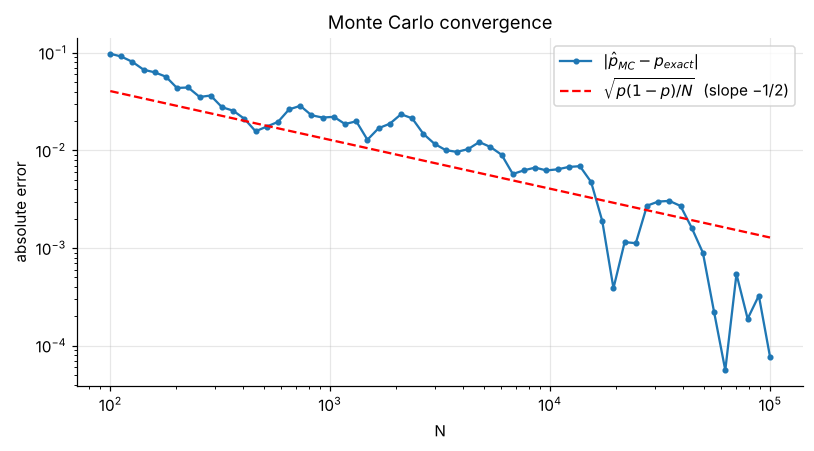

In [17]:
p_exact = stats.norm.cdf(M_SUN, mu_hat, sigma_hat)
N = 100_000
draws = np.random.default_rng(SEED).normal(mu_hat, sigma_hat, N)
p_mc = (draws < M_SUN).mean(); se = np.sqrt(p_mc * (1 - p_mc) / N)
print(f"Analytic  P(M_V < 4.83) = Φ(({M_SUN} − {mu_hat:.3f}) / {sigma_hat:.3f}) = {p_exact:.4f}")
print(f"Monte Carlo (N = {N:,}) = {p_mc:.4f} ± {se:.4f};  |error| = {abs(p_mc - p_exact) / se:.2f} SE")
print(f"Empirical share of the slice with M_V < 4.83 = {(x < M_SUN).mean():.4f}")

Ns = np.unique(np.logspace(2, 5, 60).astype(int))
err = [abs((draws[:m] < M_SUN).mean() - p_exact) for m in Ns]
plt.figure(figsize=(7.5, 4.2))
plt.loglog(Ns, err, "o-", ms=3, label=r"$|\hat p_{MC} - p_{exact}|$")
plt.loglog(Ns, np.sqrt(p_exact * (1 - p_exact) / Ns), "r--", label=r"$\sqrt{p(1-p)/N}$  (slope −1/2)")
plt.xlabel("N"); plt.ylabel("absolute error"); plt.title("Monte Carlo convergence"); plt.legend()
plt.tight_layout(); save("t9_mc_convergence"); plt.show()

**Interpretation**

* **Analytic:** $P(M_V < 4.83) = \Phi((4.83 − 4.247)/0.717) = \Phi(0.81) = 0.792$. **Monte Carlo** (N = 100,000) gives 0.7922 ± 0.0013, within 0.1 SE of the exact value. The error curve follows the $\sqrt{p(1-p)/N}$ line, confirming the $1/\sqrt N$ rate.
* **Empirically, 81.3% of the slice is brighter than the Sun**, two points more than the Gaussian predicts. The difference comes from the heavy bright tail (subgiants) that the Gaussian misses (Task 2).
* **Interpretation:** this does *not* mean that 79% of all Sun-coloured stars in the Galaxy outshine the Sun. In a magnitude-limited sample like Hipparcos, brighter stars are visible to larger distances and are over-represented (Malmquist bias), and evolved subgiants with the Sun's colour add to the bright side. A volume-limited sample would put the Sun much closer to the middle of its colour class.

## Task 11 — How parallax errors propagate into the HR diagram

$M_V = V + 5\log_{10}\pi - 10$ with $V$ exact. The first-order (delta-method) approximation $\sigma_{M_V}\approx\left|\frac{\partial M_V}{\partial \pi}\right|\sigma_\pi$ with
$\frac{\partial M_V}{\partial \pi} = \frac{5}{\pi\ln 10}$ gives

$$\sigma_{M_V} \approx \frac{5}{\ln 10}\,\frac{\sigma_\pi}{\pi} \approx 2.17\,\frac{\sigma_\pi}{\pi}, \qquad \frac{\sigma_\pi}{\pi}=0.1 \;\Rightarrow\; \sigma_{M_V}\approx 0.217 \text{ mag}.$$

The error depends only on the *relative* parallax error, so it is largest for distant stars, whose parallaxes are small.

In [18]:
hip["sigma_MV"] = 5 / np.log(10) * hip["rel_err"]
print(f"σ_MV at σπ/π = 0.1: {5 / np.log(10) * 0.1:.4f} mag")
print(f"Across the sample: median σ_MV = {hip['sigma_MV'].median():.3f}, 90th percentile = {hip['sigma_MV'].quantile(0.9):.3f} mag")
region = np.select([hip["MV"] < 2, hip["MV"] > 0.5 + 5 * hip["B-V"]], ["giants (M_V < 2)", "main sequence"], "subgiants / other")
display(hip.groupby(region).agg(stars=("MV", "size"), median_distance_pc=("Plx", lambda p: np.median(1000 / p)),
                               median_sigma_MV=("sigma_MV", "median")).round(3))

# Monte Carlo sensitivity: perturb each parallax by its own error and re-run Tasks 2, 4, 8
rng = np.random.default_rng(SEED); R = 200
res = []
for _ in range(R):
    plx = hip["Plx"].to_numpy() + rng.normal(0, hip["e_Plx"].to_numpy())
    mv = hip["Vmag"].to_numpy() + 5 * np.log10(np.clip(plx, 1e-3, None)) - 10
    s = (BV > 0.60) & (BV < 0.65)
    m_sel = (BV > 0.3) & (BV < 1.5) & (mv > 0.5 + 5 * BV)
    beta = np.polyfit(BV[m_sel], mv[m_sel], 1)
    res.append({"T2 μ": mv[s].mean(), "T2 σ": mv[s].std(), "T4 slope": beta[0], "T4 intercept": beta[1]})
res = pd.DataFrame(res)
t11 = pd.DataFrame({"observed": [mu_hat, sigma_hat, fit1["beta"][1], fit1["beta"][0]],
                    "MC mean": res.mean().values, "MC sd": res.std().values}, index=res.columns)
t11["shift"] = t11["MC mean"] - t11["observed"]
t11.round(4)

σ_MV at σπ/π = 0.1: 0.2171 mag
Across the sample: median σ_MV = 0.143, 90th percentile = 0.203 mag


,stars,median_distance_pc,median_sigma_MV
giants (M_V < 2),4744,104.822,0.162
main sequence,13362,56.818,0.134
subgiants / other,2697,78.802,0.152


,observed,MC mean,MC sd,shift
T2 μ,4.2465,4.2419,0.0039,-0.0046
T2 σ,0.7170,0.7312,0.0040,0.0143
T4 slope,5.6860,5.6730,0.0055,-0.0130
T4 intercept,0.8949,0.9080,0.0044,0.0131


### Lutz–Kelker bias: a simulation

Selecting stars on the *observed* $\sigma_\pi/\pi$ favours stars whose parallax was scattered **upwards**: there are more stars at larger distances, and a positive error moves them inside the cut.
Their distances are underestimated, so their computed $M_V$ is too faint.
A simple simulation shows the effect: stars uniformly distributed in space, all with true $M_V = 4.8$, observed with $\sigma_\pi = 1$ mas (typical for Hipparcos).

,stars,"mean (M_V,obs − M_V,true)",δ-method σ_MV
observed σπ/π,,,
0.000–0.025,485,0.006,0.027
0.025–0.050,3440,0.018,0.081
0.050–0.075,9640,0.042,0.136
0.075–0.100,19590,0.084,0.190
0.100–0.150,89337,0.194,0.271
0.150–0.200,197539,0.334,0.380


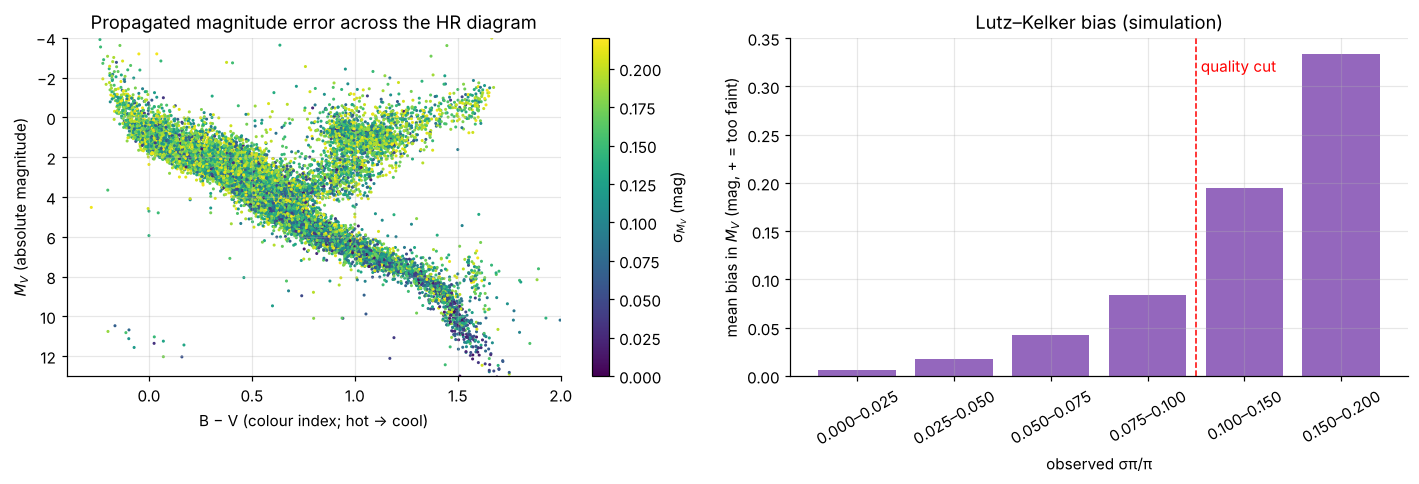

In [19]:
rng = np.random.default_rng(SEED)
n_sim = 2_000_000
d_true = 400 * rng.random(n_sim) ** (1 / 3)              # uniform density inside 400 pc
pi_true = 1000 / d_true
pi_obs = pi_true + rng.normal(0, 1.0, n_sim)
rel = 1.0 / pi_obs
mv_true = 4.8
V = mv_true + 5 * np.log10(d_true) - 5
ok = (pi_obs > 0) & (V < 12.4)                           # roughly the faint limit of the Hipparcos catalogue

lk = []
for lo, hi in [(0.0, 0.025), (0.025, 0.05), (0.05, 0.075), (0.075, 0.10), (0.10, 0.15), (0.15, 0.20)]:
    sel = ok & (rel >= lo) & (rel < hi)
    mv_obs = V[sel] + 5 * np.log10(pi_obs[sel]) - 10
    lk.append({"observed σπ/π": f"{lo:.3f}–{hi:.3f}", "stars": int(sel.sum()),
               "mean (M_V,obs − M_V,true)": (mv_obs - mv_true).mean(), "δ-method σ_MV": 2.17 * (lo + hi) / 2})
lk = pd.DataFrame(lk).set_index("observed σπ/π")
display(lk.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sc = ax[0].scatter(hip["B-V"], hip["MV"], c=hip["sigma_MV"], s=1, cmap="viridis", vmin=0, vmax=0.22)
plt.colorbar(sc, ax=ax[0], label="σ$_{M_V}$ (mag)")
hr_axes(ax[0], "Propagated magnitude error across the HR diagram"); ax[0].set_xlim(-0.4, 2.0); ax[0].set_ylim(13, -4)
ax[1].bar(lk.index, lk["mean (M_V,obs − M_V,true)"], color="tab:purple")
ax[1].axvline(3.5, color="r", ls="--", lw=1); ax[1].text(3.55, ax[1].get_ylim()[1] * 0.9, "quality cut", color="r")
ax[1].set(xlabel="observed σπ/π", ylabel="mean bias in $M_V$ (mag, + = too faint)",
          title="Lutz–Kelker bias (simulation)")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); save("t11_parallax_errors"); plt.show()

**Interpretation**

* **Delta method:** $\sigma_{M_V} = \frac{5}{\ln 10}\frac{\sigma_\pi}{\pi} \approx 2.17\,\sigma_\pi/\pi$, so **σπ/π = 0.1 gives 0.217 ≈ 0.22 mag**. Across the sample the median error is 0.14 mag (90th percentile 0.20 mag).
* **Most affected region.** The error grows with distance, because the parallax shrinks while its absolute error stays ~1 mas. **Giants** are the most affected (median σ_MV 0.16 mag, median distance 105 pc): being luminous, they enter the catalogue from further away. Nearby main-sequence dwarfs are the least affected (0.13 mag, 57 pc). The faintest M dwarfs near the bottom of the diagram are very close and have the smallest errors.
* **Effect on earlier tasks** (Monte Carlo sensitivity: each parallax perturbed by its own error, 200 repetitions):
  * **T2:** noise *inflates* σ (+0.014 mag), while μ hardly moves (−0.005). Of the observed σ² = 0.514, about 0.02 (4%) is measurement noise, so the intrinsic spread of solar-colour stars is ≈ 0.70 mag.
  * **T4:** the errors are in the *response* ($M_V$), so they add scatter but do not bias the slope directly (−0.013). A small effect comes back through the selection cut, which itself depends on $M_V$.
  * **T8:** extra scatter widens every mixture component and blurs boundaries, especially among the more distant giants (red clump vs RGB).
* **Lutz–Kelker bias (simulation).** Selecting on the *observed* σπ/π preferentially keeps stars whose parallax was scattered upwards. They look closer than they are, so their $M_V$ comes out **too faint**. In the simulation the bias is 0.04 mag for 0.05 < σπ/π < 0.075 and 0.08 mag for 0.075–0.10, about **0.06 mag on average inside the 10% cut**. Without the cut it grows to 0.19–0.33 mag. This systematic bias is *not* captured by the random σ_MV above. It mostly affects the distant giants (T5, T8) and the bright edge of T2. The 10% quality cut keeps it small, but it is the reason careful work uses Lutz–Kelker or Bayesian distance corrections, as Gaia-era analyses do.